In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

# তোর পাথ
path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'

extractors = ['AlexNet', 'CustomCNN', 'DenseNet121', 'EfficientNetB0', 'InceptionV3',
              'MobileNetV2', 'ResNet50', 'VGG16', 'ViT', 'Xception']

classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

results = pd.DataFrame(columns=['Feature Extractor'] + list(classifiers.keys()) + ['Best', 'Best Accuracy'])
results['Feature Extractor'] = extractors

for extractor in extractors:
    print(f'\nProcessing {extractor} ...')

    # ফাইল লোড
    f1_file = f'{path}F1_Features_{extractor}.csv'  # লেবেলের জন্য
    f3_file = f'{path}F3_Features_{extractor}.csv'  # ← F3
    f4_file = f'{path}F4_Features_{extractor}.csv'  # ← F4

    df1 = pd.read_csv(f1_file)  # লেবেল
    df3 = pd.read_csv(f3_file)
    df4 = pd.read_csv(f4_file)

    # লেবেল কলাম খুঁজি F1 থেকে
    possible_label_cols = ['label', 'class', 'target', 'phoneme', 'category', 'Label', 'Class', 'phoneme_label']
    label_col = None
    for col in possible_label_cols:
        if col in df1.columns:
            label_col = col
            break

    if label_col is None:
        print(f"   → F1 এ লেবেল পাওয়া যায়নি! স্কিপ করা হলো।")
        continue

    print(f"   → লেবেল পাওয়া গেছে (F1 থেকে): {label_col} → {df1[label_col].nunique()} টি ক্লাস")

    # লেবেল আলাদা করি
    y = df1[label_col]

    # ক্লিন ফাংশন
    def clean(df):
        df = df.copy()
        drop_cols = [c for c in df.columns if any(x in c.lower() for x in ['filename', 'path', 'unnamed', 'index'])]
        df.drop(columns=drop_cols, errors='ignore', inplace=True)
        return df

    df3_clean = clean(df3)
    df4_clean = clean(df4)

    # যদি F3/F4 এ লেবেল কলাম থাকে তাহলে ফেলে দিই
    if label_col in df3_clean.columns:
        df3_clean = df3_clean.drop(columns=[label_col])
    if label_col in df4_clean.columns:
        df4_clean = df4_clean.drop(columns=[label_col])

    # F3 + F4 কনক্যাট
    X = pd.concat([df3_clean.reset_index(drop=True), df4_clean.reset_index(drop=True)], axis=1)
    print(f"   → ফিচার শেপ (F3+F4): {X.shape}")

    # ট্রেন-টেস্ট স্প্লিট
    try:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
        print(f"   → Stratified স্প্লিট সফল")
    except:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        print(f"   → সাধারণ স্প্লিট করা হয়েছে")

    best_acc = 0
    best_name = ''

    for name, clf in classifiers.items():
        try:
            clf.fit(X_train, y_train)
            acc = round(accuracy_score(y_test, clf.predict(X_test)), 4)
            results.loc[results['Feature Extractor'] == extractor, name] = acc
            if acc > best_acc:
                best_acc = acc
                best_name = name
            print(f"   → {name.ljust(20)} : {acc}")
        except Exception as e:
            print(f"   → {name} ফেইল: {e}")
            results.loc[results['Feature Extractor'] == extractor, name] = 0.0

    results.loc[results['Feature Extractor'] == extractor, 'Best'] = best_name
    results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = best_acc
    print(f"   → সেরা ক্লাসিফায়ার: {best_name} → {best_acc}")

# সেভ করি
output_file = path + 'Full_Summary_Table_F3_F4.xlsx'
results.to_excel(output_file, index=False)

print('\n' + '='*70)
print('সব শেষ! F3 + F4 কম্বিনেশনের ফাইনাল রেজাল্ট তৈরি হয়ে গেছে!')
print(f"ফাইল সেভ হয়েছে: {output_file}")
display(results)

Mounted at /content/drive

Processing AlexNet ...
   → লেবেল পাওয়া গেছে (F1 থেকে): label → 2 টি ক্লাস
   → ফিচার শেপ (F3+F4): (523, 18432)
   → Stratified স্প্লিট সফল
   → AdaBoost             : 0.8857
   → Decision Tree        : 0.8476
   → Extra Trees          : 0.8667
   → Gradient Boosting    : 0.8857
   → KNN                  : 0.9048
   → Logistic Regression  : 0.9429
   → Naive Bayes          : 0.8286
   → Random Forest        : 0.8762
   → SVM                  : 0.9429
   → সেরা ক্লাসিফায়ার: Logistic Regression → 0.9429

Processing CustomCNN ...
   → লেবেল পাওয়া গেছে (F1 থেকে): label → 2 টি ক্লাস
   → ফিচার শেপ (F3+F4): (523, 200704)
   → Stratified স্প্লিট সফল
   → AdaBoost             : 0.8952
   → Decision Tree        : 0.7714
   → Extra Trees          : 0.9048
   → Gradient Boosting    : 0.8952
   → KNN                  : 0.819
   → Logistic Regression  : 0.9524
   → Naive Bayes          : 0.6571
   → Random Forest        : 0.8762
   → SVM                  : 0.9429
   → 

,Feature Extractor,AdaBoost,Decision Tree,Extra Trees,Gradient Boosting,KNN,Logistic Regression,Naive Bayes,Random Forest,SVM,Best,Best Accuracy
0,AlexNet,0.8857,0.8476,0.8667,0.8857,0.9048,0.9429,0.8286,0.8762,0.9429,Logistic Regression,0.9429
1,CustomCNN,0.8952,0.7714,0.9048,0.8952,0.819,0.9524,0.6571,0.8762,0.9429,Logistic Regression,0.9524
2,DenseNet121,0.9048,0.8571,0.8762,0.8571,0.8381,0.9048,0.8476,0.8476,0.8476,AdaBoost,0.9048
3,EfficientNetB0,0.8762,0.819,0.8667,0.8476,0.8476,0.8762,0.8857,0.8667,0.8857,Naive Bayes,0.8857
4,InceptionV3,0.8762,0.7905,0.8286,0.8762,0.819,0.8952,0.819,0.819,0.8571,Logistic Regression,0.8952
5,MobileNetV2,0.8952,0.819,0.8476,0.8476,0.9048,0.8762,0.819,0.8381,0.8571,KNN,0.9048
6,ResNet50,0.9143,0.7619,0.8571,0.8857,0.8476,0.8667,0.8381,0.8952,0.8571,AdaBoost,0.9143
7,VGG16,0.9238,0.7524,0.8857,0.8667,0.8952,0.9238,0.781,0.8762,0.9524,SVM,0.9524
8,ViT,0.8,0.7333,0.7905,0.8095,0.7524,0.8381,0.781,0.781,0.7714,Logistic Regression,0.8381
9,Xception,0.8381,0.781,0.8286,0.8667,0.8286,0.8667,0.8,0.8476,0.8571,Gradient Boosting,0.8667


Mounted at /content/drive
Best Feature Extractor: CustomCNN
Best Classifier: Logistic Regression
Feature shape: (523, 200704), Labels shape: (523,)
Train-Test split done.


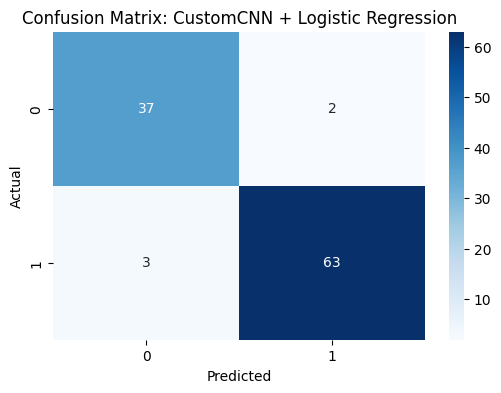


Performance Summary Table:



,Metric,Value (%)
0,Accuracy,95.24
1,Precision,94.71
2,Recall,95.16
3,F1-Score,94.93


In [10]:
# ==========================
# Step 0: Imports
# ==========================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ==========================
# Step 1: Paths & Classifiers
# ==========================
# Feature files
feature_path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'

# Accuracy summary
results_path = feature_path + 'Feature_Extract/'
results_file = results_path + 'F3+F4.xlsx'

# Classifiers dictionary
classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

# ==========================
# Step 2: Load summary results
# ==========================
results = pd.read_excel(results_file)
results.head()

# ==========================
# Step 3: Best overall accuracy
# ==========================
best_row = results.loc[results['Best Accuracy'].idxmax()]
extractor = best_row['Feature Extractor']
best_classifier_name = best_row['Best']
print(f"Best Feature Extractor: {extractor}")
print(f"Best Classifier: {best_classifier_name}")

# ==========================
# Step 4: Load F1, F3, F4 features
# ==========================
f1_file = feature_path + f'F1_Features_{extractor}.csv'
f3_file = feature_path + f'F3_Features_{extractor}.csv'
f4_file = feature_path + f'F4_Features_{extractor}.csv'

df1 = pd.read_csv(f1_file)
df3 = pd.read_csv(f3_file)
df4 = pd.read_csv(f4_file)

# Identify label column
possible_label_cols = ['label', 'class', 'target', 'phoneme', 'category', 'Label', 'Class', 'phoneme_label']
label_col = next((col for col in possible_label_cols if col in df1.columns), None)
y = df1[label_col]

# Clean feature dataframe
def clean(df):
    df = df.copy()
    drop_cols = [c for c in df.columns if any(x in c.lower() for x in ['filename','path','unnamed','index'])]
    df.drop(columns=drop_cols, errors='ignore', inplace=True)
    return df

df3_clean = clean(df3)
df4_clean = clean(df4)
if label_col in df3_clean.columns: df3_clean.drop(columns=[label_col], inplace=True)
if label_col in df4_clean.columns: df4_clean.drop(columns=[label_col], inplace=True)

X = pd.concat([df3_clean.reset_index(drop=True), df4_clean.reset_index(drop=True)], axis=1)
print(f"Feature shape: {X.shape}, Labels shape: {y.shape}")

# ==========================
# Step 5: Train-Test Split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train-Test split done.")

# ==========================
# Step 6: Train best classifier
# ==========================
clf = classifiers[best_classifier_name]
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# ==========================
# Step 7: Confusion Matrix
# ==========================
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix: {extractor} + {best_classifier_name}')
plt.show()

# ==========================
# Step 8: Performance Table (Summary as percentage)
# ==========================
accuracy = round(100 * np.mean(y_test == y_pred), 2)
precision = round(100 * precision_score(y_test, y_pred, average='macro'), 2)
recall = round(100 * recall_score(y_test, y_pred, average='macro'), 2)
f1 = round(100 * f1_score(y_test, y_pred, average='macro'), 2)

performance_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value (%)': [accuracy, precision, recall, f1]
})

print("\nPerformance Summary Table:\n")
display(performance_summary)